# Task 1 — Exploratory Data Analysis and Ridge Regression
**DSA5102 Final Project · Group 8 · WangKe (Member 1)**

How well can calendar information and weather recorded at the same time
estimate electricity demand in the three Tetouan distribution zones?
We use Ridge as the linear benchmark for the group's model comparison.

From the repository root, run `uv sync --frozen`, open this notebook and choose
the repository `.venv` interpreter. Then **Restart Kernel and Run All**.
The model, plotting and export functions are in [member1/analysis.py](member1/analysis.py).

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data/Tetuan City power consumption.csv").exists():
    raise FileNotFoundError("Open and run this notebook from the repository root.")
from member1 import analysis as m1

RESULTS = PROJECT_ROOT / "member1/results"
FIGURES = PROJECT_ROOT / "member1/figures"
RESULTS.mkdir(parents=True, exist_ok=True)
m1.setup_style()
print("Python:", sys.version.split()[0])

def display_metrics(frame):
    """Format tiny alphas without an optional table-rendering dependency."""
    pretty = frame.copy()
    for column in pretty.select_dtypes(include="number"):
        if column != "alpha":
            pretty[column] = pretty[column].round(3)
    if "alpha" in pretty:
        pretty["alpha"] = pretty["alpha"].map(lambda a: "—" if pd.isna(a) else f"{a:g}")
    display(pretty)

Matplotlib is building the font cache; this may take a moment.


Python: 3.11.1


## 1. Data Preprocessing
The [UCI Power Consumption of Tetouan City dataset](https://archive.ics.uci.edu/dataset/849/power%2Bconsumption%2Bof%2Btetouan%2Bcity)
describes three distribution networks in northern Morocco. This CSV has one
timestamp, five weather/radiation-related inputs and three demand targets.
The CSV contains **52,416 rows** from 1 January to 30 December 2017.
We standardize column names, parse the timestamps and check for missing
values, duplicates and gaps. Demand is reported in the source data units.

In [2]:
data, audit = m1.audit_data(PROJECT_ROOT)
m1.write_json(RESULTS / "data_audit.json", audit)
display(pd.Series({key: audit[key] for key in
                   ["rows", "columns", "time_start", "time_end", "complete_days", "cleaning"]}))
display(pd.Series(audit["checks"], name="Passed"))
display(data.head())

rows                                                         52416
columns                                                          9
time_start                                     2017-01-01 00:00:00
time_end                                       2017-12-30 23:50:00
complete_days                                                  364
cleaning         Rename columns only; no imputation, deletion o...
dtype: object

no_missing_values            True
all_numeric_values_finite    True
timestamps_sorted_unique     True
regular_10min_grid           True
364_complete_days            True
no_duplicate_rows            True
Name: Passed, dtype: bool

,temperature,humidity,wind_speed,general_diffuse_flows,diffuse_flows,zone_1,zone_2,zone_3
timestamp,,,,,,,,
2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


All 364 observed dates have 144 unique ten-minute records, with no missing
values, duplicate timestamps or gaps. The CSV ends on **30 December**.

In [3]:
dictionary = pd.DataFrame({
    "field": ["timestamp", *m1.WEATHER, *m1.TARGETS],
    "role": ["calendar input", *(["observed weather input"] * 5), *(["target only"] * 3)],
    "use": ["recorded calendar", "temperature", "humidity", "wind speed",
            "general diffuse flows", "diffuse flows", "network 1 demand",
            "network 2 demand", "network 3 demand"],
})
display(dictionary)

,field,role,use
0,timestamp,calendar input,recorded calendar
1,temperature,observed weather input,temperature
2,humidity,observed weather input,humidity
3,wind_speed,observed weather input,wind speed
4,general_diffuse_flows,observed weather input,general diffuse flows
5,diffuse_flows,observed weather input,diffuse flows
6,zone_1,target only,network 1 demand
7,zone_2,target only,network 2 demand
8,zone_3,target only,network 3 demand


## 2. Exploratory Data Analysis
We use the data through 18 October to examine daily trends, hours of peak
demand, weekday patterns and associations with weather. The daily trend shows
mean demand. Shading on the daily profiles spans the 10th to 90th percentiles
across dates.

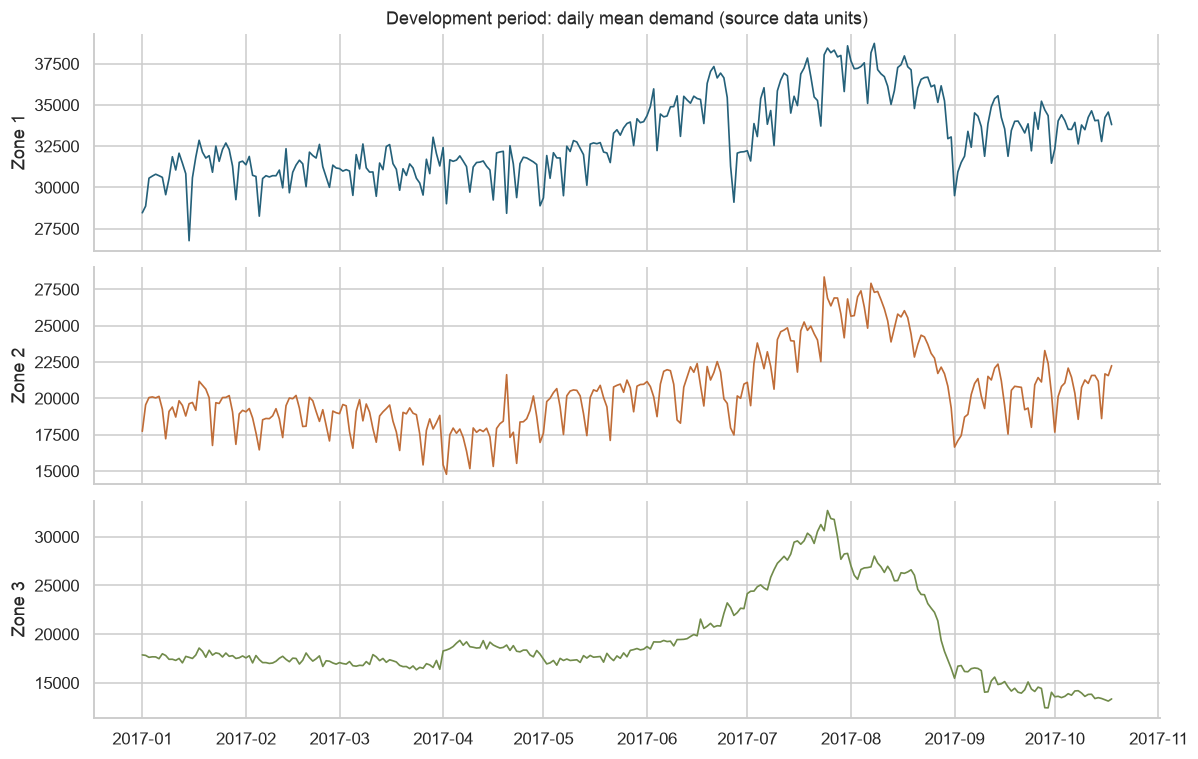

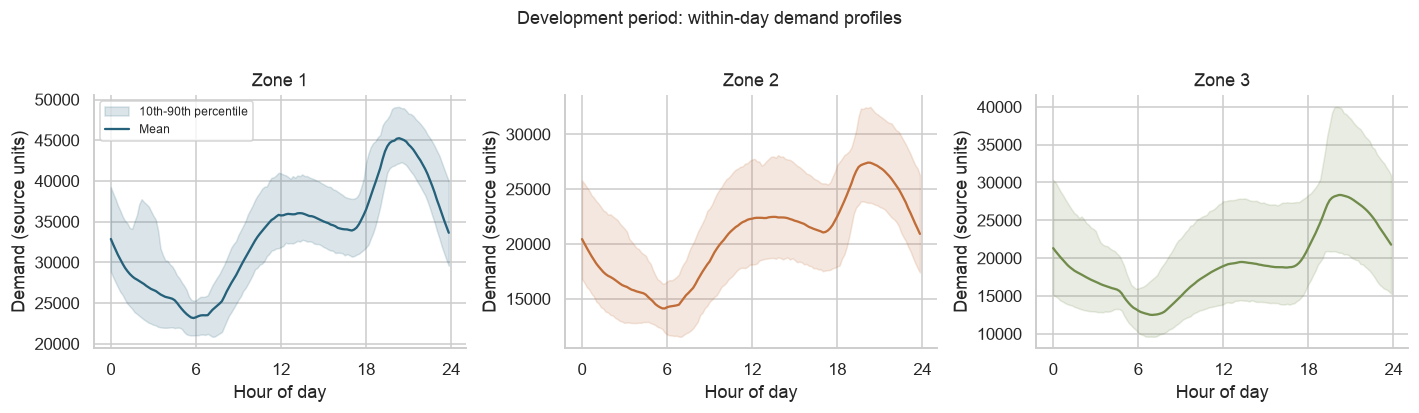

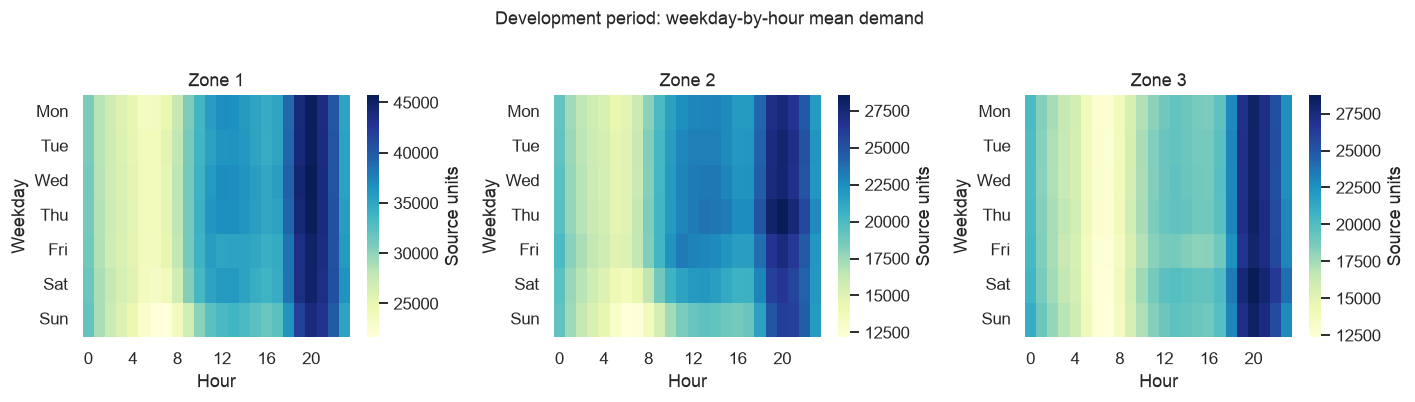

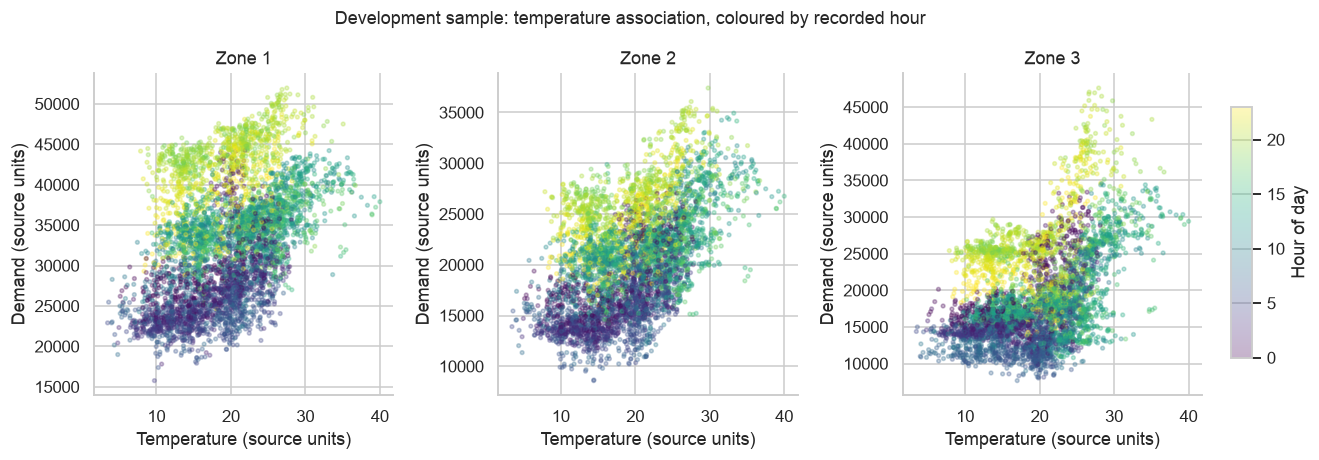

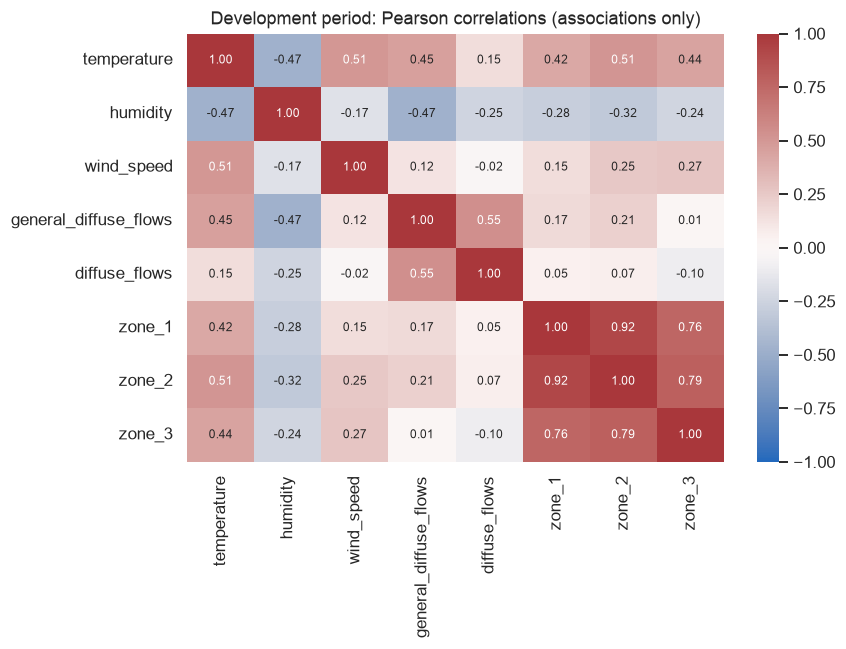

In [4]:
development, holdout = m1.split_data(data)
eda_figures = m1.plot_eda(development, FIGURES)
for name, figure in eda_figures.items():
    display(figure)
    plt.close(figure)

In [5]:
fractional_hour = development.index.hour + development.index.minute / 60
mean_profile = development[m1.TARGETS].groupby(fractional_hour).mean()
display(pd.DataFrame({"mean_profile_peak_hour": mean_profile.idxmax(),
                      "mean_profile_trough_hour": mean_profile.idxmin(),
                      "temperature_correlation": development[m1.WEATHER + m1.TARGETS].corr()
                          .loc["temperature", m1.TARGETS]}).rename(index=m1.LABELS).round(3))
display(development[m1.TARGETS].corr().round(3))

,mean_profile_peak_hour,mean_profile_trough_hour,temperature_correlation
Zone 1,20.333,5.833,0.418
Zone 2,20.167,5.833,0.515
Zone 3,20.167,7.000,0.443


,zone_1,zone_2,zone_3
zone_1,1.000,0.921,0.760
zone_2,0.921,1.000,0.789
zone_3,0.760,0.789,1.000


**Observations and modeling implications.** All three mean daily profiles peak
around **20:10–20:20**, motivating cyclic daily features. Early-morning troughs
and weekday patterns support the inclusion of calendar information. Zones 1
and 2 have a demand correlation of **0.921**.
Zone 3 shows a pronounced mid-year rise and subsequent decline; a smooth annual
basis may not explain that change adequately.

Temperature has positive marginal correlations of about **0.418 / 0.515 / 0.443**
with the three targets. The hour-coloured scatter shows how temperature and
time of day vary together, so we compare time-only and time-plus-weather models.

## 3. Feature Engineering
We compare three sets of inputs to see what weather and interactions add
once the model already has calendar information.

| Feature set | Inputs | Features |
|---|---|---:|
| R1 | Three daily sine/cosine pairs, weekday indicators and annual sine/cosine | 14 |
| R2 | R1 + the five weather fields | 19 |
| R3 | R2 + T², T×humidity, T×daily sin/cos k=1 | 23 |

Fractional hours preserve ten-minute resolution. The daily sine and cosine
terms put 23:50 and 00:00 close together. Monday is the weekday reference.
Annual sine and cosine terms allow a smooth seasonal pattern within 2017.

In [6]:
example_x = m1.make_features(development, "R3")
display(example_x.head(3))

,daily_sin_1,daily_cos_1,daily_sin_2,daily_cos_2,daily_sin_3,daily_cos_3,weekday_1,weekday_2,weekday_3,weekday_4,...,annual_cos,temperature,humidity,wind_speed,general_diffuse_flows,diffuse_flows,temperature_squared,temperature_x_humidity,temperature_x_daily_sin,temperature_x_daily_cos
timestamp,,,,,,,,,,,,,,,,,,,,,
2017-01-01 00:00:00,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.0,0.0,0.0,0.0,...,1.0,6.559,73.8,0.083,0.051,0.119,43.020481,484.0542,0.000000,6.559000
2017-01-01 00:10:00,0.043619,0.999048,0.087156,0.996195,0.130526,0.991445,0.0,0.0,0.0,0.0,...,1.0,6.414,74.5,0.083,0.070,0.085,41.139396,477.8430,0.279775,6.407895
2017-01-01 00:20:00,0.087156,0.996195,0.173648,0.984808,0.258819,0.965926,0.0,0.0,0.0,0.0,...,1.0,6.313,74.5,0.080,0.062,0.100,39.853969,470.3185,0.550214,6.288977


## 4. Ridge Regression
The baseline (B0) predicts each zone's mean demand from the training data.
We train a separate Ridge model for each zone and feature set. Ridge minimizes

$$\sum_{i\in\mathrm{train}} (y_i-b-\boldsymbol\phi(x_i)^T w)^2
   +\alpha\lVert w\rVert_2^2.$$

Here, `alpha` controls the penalty on the feature coefficients. The
intercept is unpenalized. Ridge is linear in the fitted coefficients,
including those on temperature squared and the interaction terms.
The pipeline standardizes continuous features and keeps weekday indicators as 0 or 1.

In [7]:
display(m1.ridge_pipeline(example_x.columns))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('continuous', ...), ('weekday', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{fea

## 5. Performance Evaluation

### Cross-validation and model selection
We use **1 January–18 October** to select the model and
**19 October–30 December** for the final test. Each of five expanding
training windows is followed by 28 days of validation. The scaler is fitted
on the training data within each fold.

For each zone and feature set, `GridSearchCV` tests **10⁻⁴, 10⁻³, …, 10⁶**
and picks the alpha with the lowest mean validation RMSE. We then average
the three zone RMSEs to choose one feature set, and report zone scores
individually because the absolute error scales differ.

In [8]:
_, fold_table = m1.cv_splits(development)
display(fold_table)

,fold,train_start,train_end,train_rows,train_days,validation_start,validation_end,validation_rows,validation_days
0,1,2017-01-01 00:00:00,2017-05-31 23:50:00,21744,151,2017-06-01 00:00:00,2017-06-28 23:50:00,4032,28
1,2,2017-01-01 00:00:00,2017-06-28 23:50:00,25776,179,2017-06-29 00:00:00,2017-07-26 23:50:00,4032,28
2,3,2017-01-01 00:00:00,2017-07-26 23:50:00,29808,207,2017-07-27 00:00:00,2017-08-23 23:50:00,4032,28
3,4,2017-01-01 00:00:00,2017-08-23 23:50:00,33840,235,2017-08-24 00:00:00,2017-09-20 23:50:00,4032,28
4,5,2017-01-01 00:00:00,2017-09-20 23:50:00,37872,263,2017-09-21 00:00:00,2017-10-18 23:50:00,4032,28


In [9]:
development_result = m1.run_development(development, RESULTS)
display_metrics(development_result["summary"])
display(development_result["cv_macro_rmse"].rename("Mean zone CV RMSE").round(3))
primary = development_result["primary_model"]
print("CV-selected feature set:", primary)

R1 / zone_1: alpha=1000, CV RMSE=3524.80


R1 / zone_2: alpha=1000, CV RMSE=3520.03


R1 / zone_3: alpha=1000, CV RMSE=6876.94


R2 / zone_1: alpha=1000, CV RMSE=3508.90


R2 / zone_2: alpha=1000, CV RMSE=3459.75


R2 / zone_3: alpha=10000, CV RMSE=6635.58


... (2 outputs left out)

R3 / zone_3: alpha=0.0001, CV RMSE=5877.54


,model,zone,alpha,mean_rmse,std_rmse,mean_mae,mean_r2
0,B0,zone_1,—,7507.274,813.453,6276.395,-0.186
1,B0,zone_2,—,5561.001,1565.530,4683.504,-0.475
2,B0,zone_3,—,8070.697,2644.345,6826.200,-1.559
3,R1,zone_1,1000,3524.800,1374.721,2734.213,0.719
4,R1,zone_2,1000,3520.028,1248.944,2984.055,0.320
5,R1,zone_3,1000,6876.938,3370.897,6196.638,-1.962
6,R2,zone_1,1000,3508.895,1390.042,2716.937,0.720
7,R2,zone_2,1000,3459.753,1137.078,2908.897,0.352
8,R2,zone_3,10000,6635.577,2588.970,5942.818,-1.527
9,R3,zone_1,10000,3578.847,1216.897,2783.936,0.718


model
B0    7046.324
R1    4640.589
R2    4534.742
R3    4278.467
Name: Mean zone CV RMSE, dtype: float64

CV-selected feature set: R3


Mean validation RMSE falls from **4,640.59 (R1)** to **4,534.74 (R2)** and
**4,278.47 (R3)**. R3 gains most in Zone 3, while R2 has the lowest validation
RMSE in Zone 1. The selected R3 alphas are **10,000 / 0.0001 / 0.0001** for
Zones 1/2/3. Zones 2 and 3 selected the smallest value in the grid.

### Test results and error analysis
We fit each configuration on the full development period and evaluate it
on the year-end test set. RMSE gives more weight to large errors, and MAE
reports the average absolute error. Both use the original demand scale.

In [10]:
final_metrics, holdout_predictions = m1.evaluate_holdout(
    development, holdout, development_result, RESULTS)
test_metrics = final_metrics.query("split == 'holdout'")
display_metrics(test_metrics)
display(test_metrics.groupby("model")[["rmse", "mae", "r2"]].mean().round(3))

,model,zone,alpha,split,rmse,mae,r2
0,B0,zone_1,—,holdout,7142.635,6004.852,-0.344
2,B0,zone_2,—,holdout,6159.643,4996.032,-0.261
4,B0,zone_3,—,holdout,7900.139,7223.548,-4.749
6,R1,zone_1,1000,holdout,3769.688,3267.309,0.626
8,R1,zone_2,1000,holdout,4117.825,3286.677,0.437
10,R1,zone_3,1000,holdout,4486.595,3984.168,-0.854
12,R2,zone_1,1000,holdout,3626.961,3138.860,0.653
14,R2,zone_2,1000,holdout,4345.852,3525.398,0.372
16,R2,zone_3,10000,holdout,4499.392,4092.746,-0.865
18,R3,zone_1,10000,holdout,3671.028,3231.856,0.645


,rmse,mae,r2
model,,,
B0,7067.472,6074.811,-1.785
R1,4124.703,3512.718,0.069
R2,4157.401,3585.668,0.054
R3,3909.604,3320.731,0.274


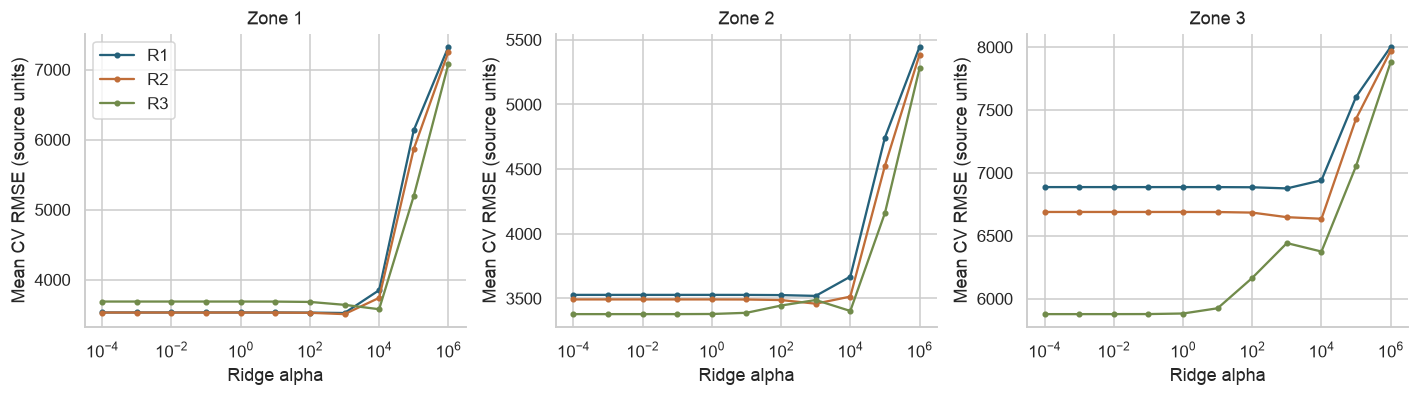

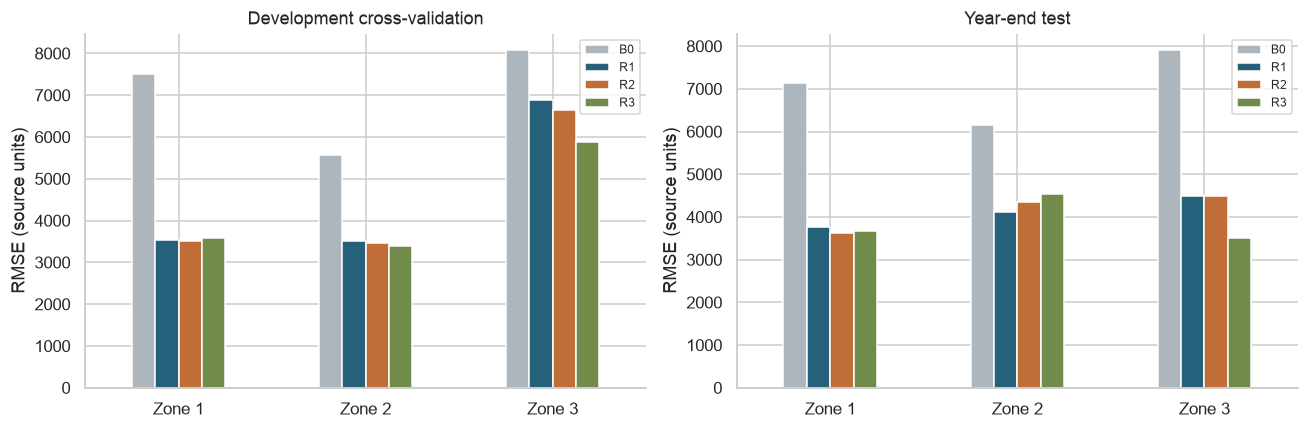

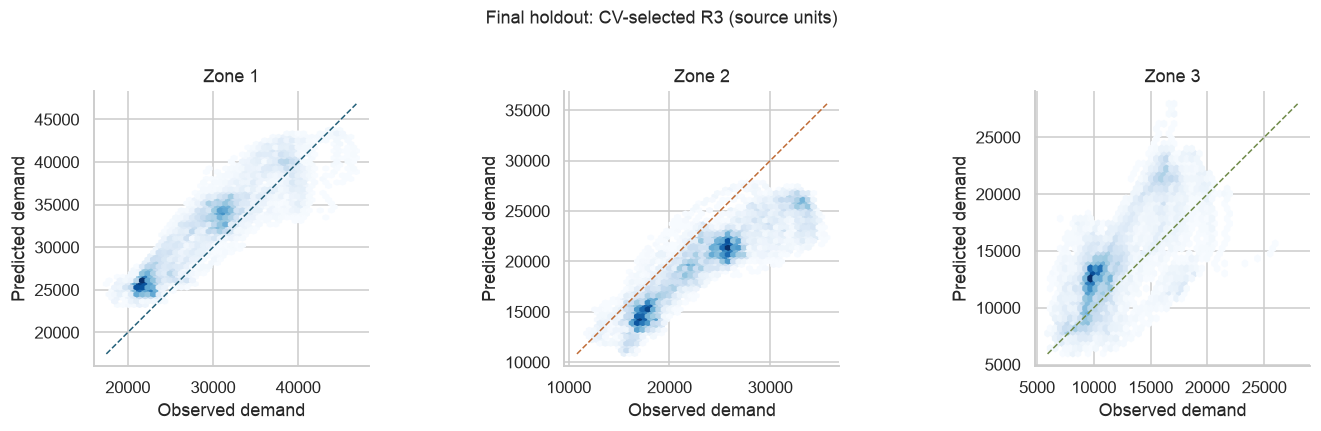

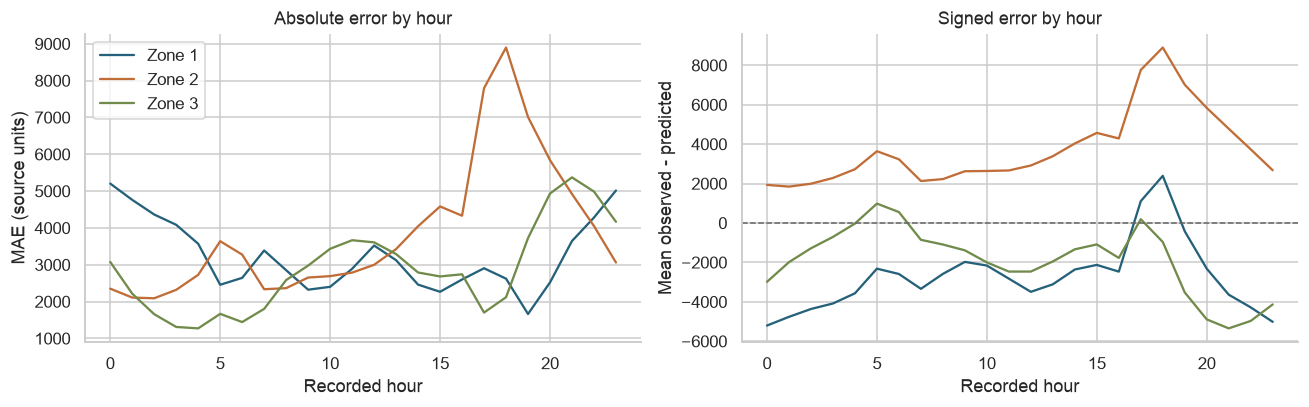

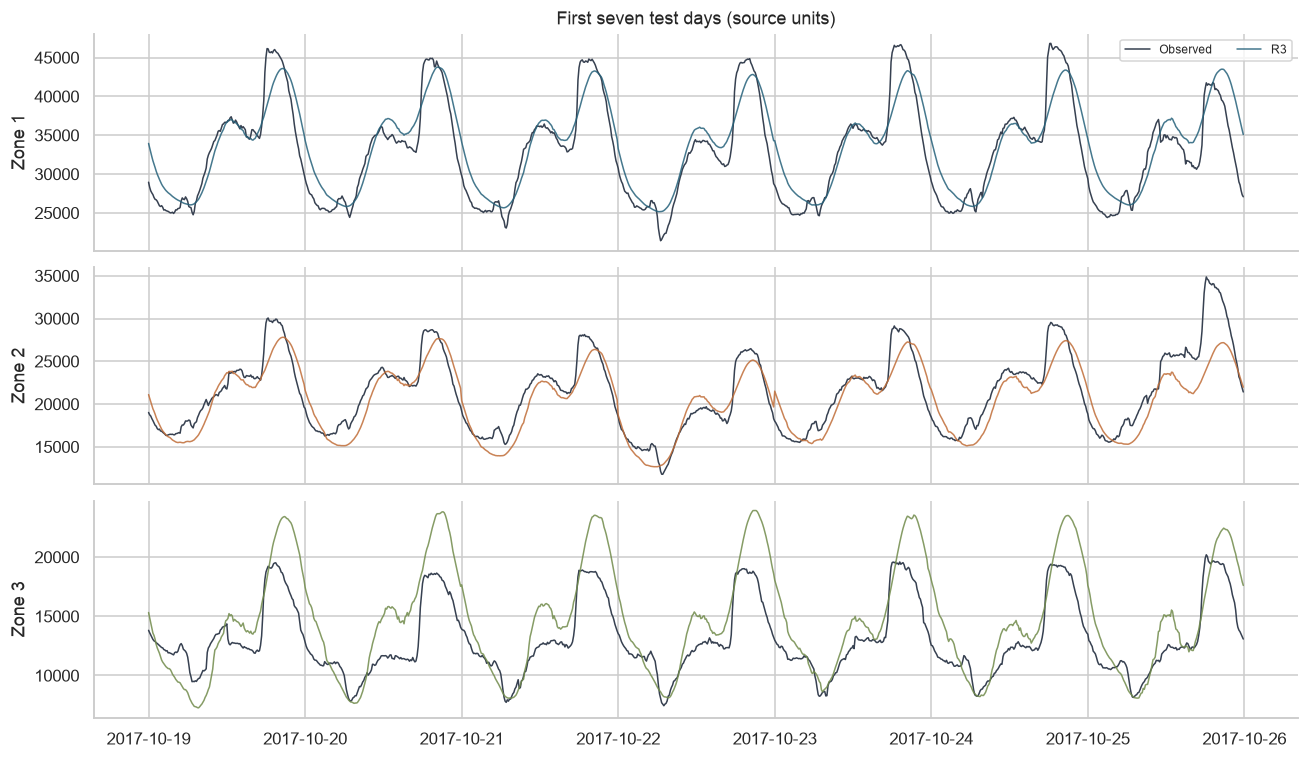

In [11]:
result_figures = m1.plot_results(development_result, final_metrics, holdout_predictions, FIGURES)
for name, figure in result_figures.items():
    display(figure)
    plt.close(figure)

In [12]:
primary_scores = test_metrics.query("model == @primary").set_index("zone")
baseline_scores = test_metrics.query("model == 'B0'").set_index("zone")
improvement = 100 * (1 - primary_scores.rmse / baseline_scores.rmse)
display(primary_scores[["rmse", "mae", "r2"]]
        .assign(rmse_reduction_vs_B0_percent=improvement).rename(index=m1.LABELS).round(3))
m1.diagnostic_tables(development, holdout, holdout_predictions, primary, RESULTS)

,rmse,mae,r2,rmse_reduction_vs_B0_percent
zone,,,,
Zone 1,3671.028,3231.856,0.645,48.604
Zone 2,4545.982,3846.105,0.313,26.197
Zone 3,3511.803,2884.231,-0.136,55.548


,zone,hour,n,mae,bias
0,zone_1,0,438,5203.927296,-5203.927296
1,zone_1,1,438,4761.859509,-4761.859509
2,zone_1,2,438,4364.031500,-4364.031500
3,zone_1,3,438,4084.479979,-4084.479979
4,zone_1,4,438,3569.449102,-3568.565258
...,...,...,...,...,...
67,zone_3,19,438,3723.112066,-3525.177465
68,zone_3,20,438,4934.235324,-4891.533280
69,zone_3,21,438,5372.154549,-5346.513574
70,zone_3,22,438,4987.100997,-4969.553623


R3 lowers the average test RMSE from **4,124.70** for calendar-only Ridge
to **3,909.60**, a reduction of **5.2%**. Relative to B0, the RMSE reductions
are **48.6%, 26.2% and 55.5%** for Zones 1, 2 and 3.
Zone 3 still has an **R² of −0.136**. B0 uses the development-period mean.
R² uses the test-period mean as its reference, and that reference has lower
squared error than R3 in Zone 3.

On the test set, R2 has the lowest RMSE in Zone 1, R1 in Zone 2 and R3 in
Zone 3. The hourly residuals show that R3 underestimates Zone 2 demand
around the evening peak. These differences give the team's nonlinear
models concrete cases to compare.

### Conclusion
Calendar, weather and interaction features give the lowest average validation
RMSE among the Ridge configurations. The year-end results show where the
linear benchmark struggles, particularly with variation in Zone 3 and the
evening peak in Zone 2.

The data cover one city and 364 days. The year-end test measures performance
on later dates in 2017. A second year would allow a separate test of seasonal
generalization.

## Appendix

### Files for the other tasks
The prediction files include **residual = observed − predicted** and a `date`
field for joining to daily clusters. Validation-fold predictions cover
1 June–18 October and use the hyperparameters selected on those folds.

Daily load curves use the hourly mean of six ten-minute readings per zone:
**364 dates × 72 features**, ordered by zone and hour. These curves describe
completed days for PCA and clustering. The shared dates and feature functions
are documented in [member1/README.md](member1/README.md).

In [13]:
m1.export_handoff(data, development, development_result, RESULTS)
display(pd.read_csv(RESULTS / "daily_load_72d.csv", nrows=3))

,date,zone_1_h00,zone_1_h01,zone_1_h02,zone_1_h03,zone_1_h04,zone_1_h05,zone_1_h06,zone_1_h07,zone_1_h08,...,zone_3_h14,zone_3_h15,zone_3_h16,zone_3_h17,zone_3_h18,zone_3_h19,zone_3_h20,zone_3_h21,zone_3_h22,zone_3_h23
0,2017-01-01,29197.974683,24657.215190,22083.037973,20811.139240,20475.949367,20807.088607,21648.607595,18540.759495,19605.063290,...,16873.253013,16594.698795,16388.433733,22275.662650,25729.156627,26186.024095,26493.493978,25344.578313,22582.168673,19578.795180
1,2017-01-02,25303.291138,22512.405062,20945.822783,20097.215188,20066.835442,20838.481012,23307.341773,22895.189872,24368.607595,...,18274.698795,16510.843372,16346.987953,22448.192772,25507.469882,25545.060243,25642.409638,25002.409638,22839.518073,19941.204818
2,2017-01-03,25269.873417,22636.962025,21371.139242,20557.974682,20116.455698,21034.936710,24105.316455,24204.556960,25145.316457,...,16531.084337,16480.963857,16620.722892,22138.795180,25638.554217,25804.337348,26079.036145,25181.686748,23210.602410,19941.204818


### Contribution and references
**WangKe (Member 1):** data auditing and preprocessing,
exploratory visualizations, calendar/weather feature engineering, Ridge baselines,
chronological cross-validation and performance/error analysis, reproducible handoff
outputs for the other team tasks.

**Dataset:** Salam, A. & El Hibaoui, A. (2018). *Power Consumption of Tetouan City*.
UCI Machine Learning Repository. [DOI: 10.24432/C5B034](https://doi.org/10.24432/C5B034).
CC BY 4.0. The CSV is included in the group repository.

**Course:** DSA5102 Lectures 1–3 (linear basis models, kernels, CV/ensembles),
Lectures 6–8 (generalization, PCA and clustering), and the Final Group Project instructions.

**Implementation references:**
[Ridge objective](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html),
[TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html),
[preprocessing and leakage](https://scikit-learn.org/stable/common_pitfalls.html).
See [member1/README.md](member1/README.md) for run instructions and file descriptions.